In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install -q ultralytics
from ultralytics import YOLO
import torch
print('CUDA disponible :', torch.cuda.is_available())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 8.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
CUDA disponible : True


In [3]:
import os, shutil

drive_runs = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/runs/xview_yolov8s_merged_v3"
local_runs = "/content/xView_local/runs/xview_yolov8s_merged_v3"

assert os.path.exists(drive_runs), f"Dossier introuvable sur Drive : {drive_runs}"

os.makedirs(os.path.dirname(local_runs), exist_ok=True)
if not os.path.exists(local_runs):
    shutil.copytree(drive_runs, local_runs)
    print("Copie du run terminée.")
else:
    print("Run déjà présent en local.")

Copie du run terminée.


In [4]:
WEIGHTS_PATH = f"{local_runs}/weights/best.pt"
assert os.path.exists(WEIGHTS_PATH), f"best.pt introuvable : {WEIGHTS_PATH}"

model = YOLO(WEIGHTS_PATH)
print(f"Modèle chargé : {len(model.names)} classes")
print(model.names)

Modèle chargé : 29 classes
{0: 'Aircraft', 1: 'Aircraft Hangar', 2: 'Boat', 3: 'Building', 4: 'Bus', 5: 'Construction Equipment', 6: 'Construction Site', 7: 'Container Ship', 8: 'Damaged Building', 9: 'Engineering Vehicle', 10: 'Excavator', 11: 'Facility', 12: 'Front loader/Bulldozer', 13: 'Helicopter', 14: 'Helipad', 15: 'Hut/Tent', 16: 'Oil Tanker', 17: 'Passenger Vehicle', 18: 'Pylon', 19: 'Rail Vehicle', 20: 'Shed', 21: 'Shipping Container', 22: 'Shipping container lot', 23: 'Small Car', 24: 'Storage Tank', 25: 'Tower', 26: 'Trailer', 27: 'Truck', 28: 'Vehicle Lot'}


In [6]:
drive_images_dir = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/change_detection"

path_avant = f"{drive_images_dir}/avant.png"
path_apres = f"{drive_images_dir}/apres.png"

for label, path in [("avant", path_avant), ("apres", path_apres)]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"❌ Image '{label}' introuvable à l'emplacement attendu : {path}\n"
            f"Vérifie que le fichier existe bien dans le dossier '{drive_images_dir}' "
            f"et qu'il porte exactement le nom '{os.path.basename(path)}'."
        )

print("✅ Les deux images (avant/après) sont bien présentes.")

✅ Les deux images (avant/après) sont bien présentes.


In [23]:
from PIL import Image
import numpy as np
import torch
from torchvision.ops import batched_nms

CONF_THRESHOLD = 0.15
IOU_THRESHOLD_TUILE = 0.3
IOU_THRESHOLD_GLOBAL = 0.4
TAILLE_TUILE = 640
RECOUVREMENT = 200

def decouper_en_tuiles(image_path, taille=TAILLE_TUILE, recouvrement=RECOUVREMENT):
    img = Image.open(image_path).convert("RGB")
    w, h = img.size
    pas = taille - recouvrement
    tuiles = []
    for y in range(0, max(h - taille, 0) + pas, pas):
        for x in range(0, max(w - taille, 0) + pas, pas):
            x2, y2 = min(x + taille, w), min(y + taille, h)
            x1, y1 = max(0, x2 - taille), max(0, y2 - taille)
            tuiles.append((img.crop((x1, y1, x2, y2)), x1, y1))
    return tuiles, (w, h)

def inference_par_tuiles(image_path):
    tuiles, (w_total, h_total) = decouper_en_tuiles(image_path)
    boxes_g, scores_g, classes_g = [], [], []

    for tuile, offset_x, offset_y in tuiles:
        res = model.predict(source=np.array(tuile), conf=CONF_THRESHOLD,
                             iou=IOU_THRESHOLD_TUILE, verbose=False)[0]
        if len(res.boxes) == 0:
            continue
        xyxy = res.boxes.xyxy.cpu().numpy()
        xyxy[:, [0, 2]] += offset_x
        xyxy[:, [1, 3]] += offset_y
        boxes_g.append(xyxy)
        scores_g.append(res.boxes.conf.cpu().numpy())
        classes_g.append(res.boxes.cls.cpu().numpy())

    if not boxes_g:
        return np.empty((0, 4)), np.empty(0), np.empty(0), (w_total, h_total)

    boxes_g = np.vstack(boxes_g)
    scores_g = np.concatenate(scores_g)
    classes_g = np.concatenate(classes_g)

    keep = batched_nms(torch.tensor(boxes_g), torch.tensor(scores_g),
                        torch.tensor(classes_g), IOU_THRESHOLD_GLOBAL).numpy()

    return boxes_g[keep], scores_g[keep], classes_g[keep], (w_total, h_total)

boxes_avant, scores_avant, classes_avant, taille_avant = inference_par_tuiles(path_avant)
boxes_apres, scores_apres, classes_apres, taille_apres = inference_par_tuiles(path_apres)

print(f"Avant : {len(boxes_avant)} objets détectés après fusion des tuiles")
print(f"Après : {len(boxes_apres)} objets détectés après fusion des tuiles")

Avant : 8 objets détectés après fusion des tuiles
Après : 7 objets détectés après fusion des tuiles


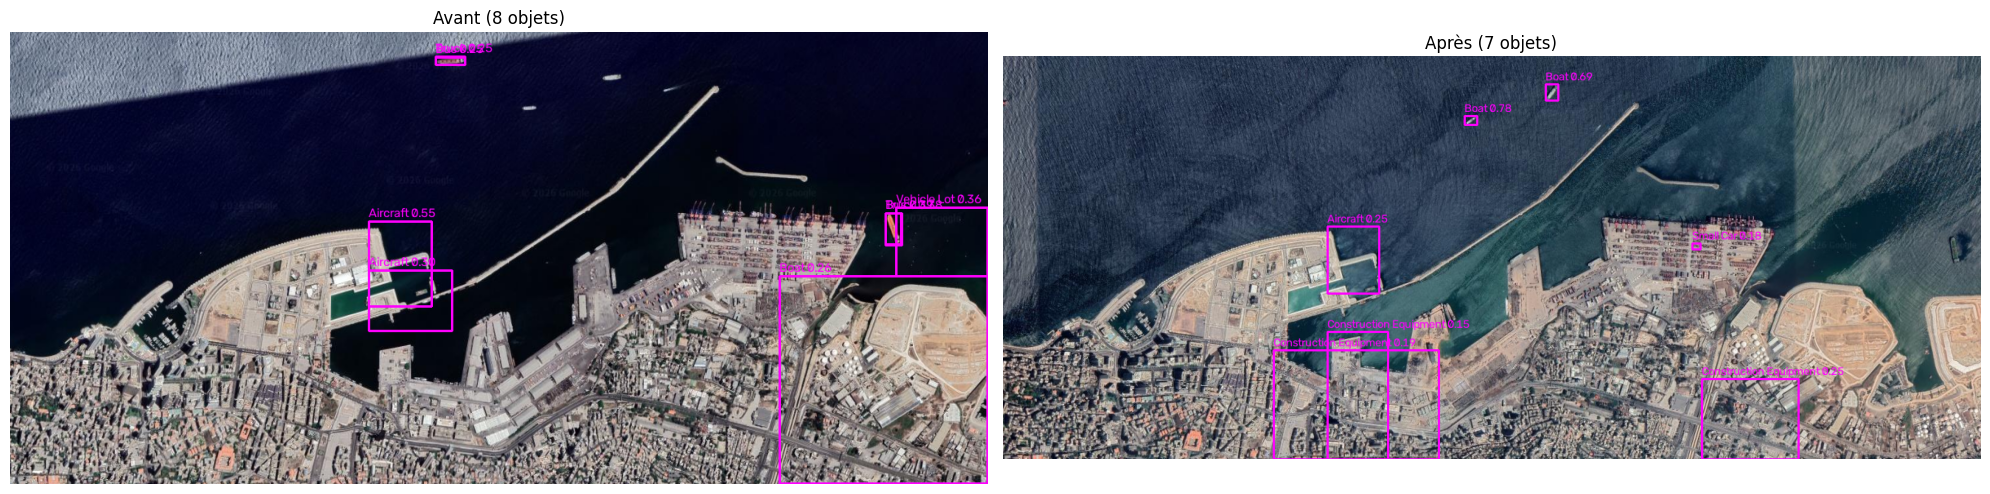

In [24]:
import cv2

def dessiner_boites(image_path, boxes, scores, classes, names):
    img = cv2.cvtColor(np.array(Image.open(image_path).convert("RGB")), cv2.COLOR_RGB2BGR)
    for (x1, y1, x2, y2), s, c in zip(boxes, scores, classes):
        p1, p2 = (int(x1), int(y1)), (int(x2), int(y2))
        cv2.rectangle(img, p1, p2, (255, 0, 255), 2)
        label = f"{names[int(c)]} {s:.2f}"
        cv2.putText(img, label, (p1[0], max(p1[1] - 5, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 255), 1)
    return img

img_avant_annotee = dessiner_boites(path_avant, boxes_avant, scores_avant, classes_avant, model.names)
img_apres_annotee = dessiner_boites(path_apres, boxes_apres, scores_apres, classes_apres, model.names)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].imshow(cv2.cvtColor(img_avant_annotee, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Avant ({len(boxes_avant)} objets)")
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(img_apres_annotee, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Après ({len(boxes_apres)} objets)")
axes[1].axis('off')
plt.tight_layout()
plt.show()

In [25]:
def compter_par_classe_np(classes, names):
    return Counter(names[int(c)] for c in classes)

count_avant = compter_par_classe_np(classes_avant, model.names)
count_apres = compter_par_classe_np(classes_apres, model.names)
toutes_classes = sorted(set(count_avant) | set(count_apres))

print(f"{'Classe':<22}{'Avant':>7}{'Après':>7}{'Delta':>7}   Statut")
print("-" * 55)
for classe in toutes_classes:
    n_avant, n_apres = count_avant.get(classe, 0), count_apres.get(classe, 0)
    delta = n_apres - n_avant
    statut = "🔴 disparu" if delta < 0 else "🟢 apparu" if delta > 0 else "⚪ inchangé"
    print(f"{classe:<22}{n_avant:>7}{n_apres:>7}{delta:>+7}   {statut}")

NameError: name 'Counter' is not defined